## Setup and Imports

In [1]:
# Title: Imports

import sys
from pathlib import Path

# Add parent directory to path for imports
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import laspy
import numpy as np
import pandas as pd
from pyntcloud import PyntCloud
import matplotlib.pyplot as plt

from lidar_preprocessing import PreprocessingConfig, process_las, batch_process

print(f"✅ Project root: {PROJECT_ROOT}")
print("✅ Imports successful (including lidar_preprocessing)")

✅ Project root: /home/nvidia/projects/fvc_structure/phase_5_3d_cnn_training
✅ Imports successful (including lidar_preprocessing)


## Configuration

In [2]:
# Title: Input directory containing LAS files with structure + treeID (PLY-only, no NPZ)

from pathlib import Path

# Input directory containing LAS files with structure + treeID
# SITE01 
# INPUT_DIR = Path("/data/calperumResearch/site1_1_DD0001/lidar/clipped/3d_structure_mask_malleid")
# INPUT_DIR = Path("/data/calperumResearch/site1_1_DD0001/lidar_l2/clipped/3d_structure_mask_malleid")

# SITE11 
# INPUT_DIR = Path("/data/calperumResearch/site2_1_DD0011/lidar/clipped/3d_structure_mask_malleid")
INPUT_DIR = Path("/data/calperumResearch/site2_1_DD0011/lidar_l2/clipped/3d_structure_mask_malleid")


# Output directories
#site01
# OUT_PLY_DIR = Path("/data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/forestformer3d_ply/")
# OUT_PLY_DIR = Path("/data/calperumResearch/site1_1_DD0001/lidar_l2/clipped/preprocessed/forestformer3d_ply/")

#site11
# OUT_PLY_DIR = Path("/data/calperumResearch/site2_1_DD0011/lidar/clipped/preprocessed/forestformer3d_ply/")
OUT_PLY_DIR = Path("/data/calperumResearch/site2_1_DD0011/lidar_l2/clipped/preprocessed/forestformer3d_ply/")

OUT_PLY_DIR.mkdir(parents=True, exist_ok=True)

# Processing parameters
VOXEL_SIZE = 0.10  # 10 cm voxels
IGNORE_INDEX = -100  # PyTorch convention for ignored labels

# IMPORTANT for ForestFormer3D/ForAINetV2 tooling: avoid `semantic_seg=0` in the PLY.
# Some exporters do `label_ids = semantic_seg - 1`, which would turn 0 -> -1.
#
# We keep the SAME 5 ecology classes, but shift their IDs to 1..5 in the PLY:
#   1=Forb, 2=Woody debris, 3=Hummock, 4=Shrub, 5=Mallee

# Class mapping: LAS classification codes -> PLY semantic_seg IDs (1..5)
CLASS_REMAP = {
    64: 1,  # Forb
    65: 2,  # Woody debris
    66: 3,  # Hummock
    67: 4,  # Shrub
    68: 5,  # Mallee
    0: IGNORE_INDEX,  # Unmatched / background (dropped from PLY)
}

config = PreprocessingConfig(
    input_dir=INPUT_DIR,
    out_ply_dir=OUT_PLY_DIR,
    voxel_size=VOXEL_SIZE,
    ignore_index=IGNORE_INDEX,
    class_remap=CLASS_REMAP,
    save_npz=False,
    out_npz_dir=None,
    ply_use_local_coords=True,
 )

print(config)

PreprocessingConfig(
  input_dir=/data/calperumResearch/site2_1_DD0011/lidar_l2/clipped/3d_structure_mask_malleid,
  out_npz_dir=None,
  out_ply_dir=/data/calperumResearch/site2_1_DD0011/lidar_l2/clipped/preprocessed/forestformer3d_ply,
  save_npz=False,
  ply_use_local_coords=True,
  save_ply_offset=True,
  voxel_size=0.1,
  num_classes=5,
  ignore_index=-100
)


## Preprocessing Functions

In [3]:
# Title: Preprocessing Functions (from lidar_preprocessing)

from lidar_preprocessing import (
    normalise_intensity,
    get_z_norm,
    remap_classes,
    get_tree_ids,
    write_forestformer_ply,
    process_las,
    batch_process,
)

print("✅ Using preprocessing functions from lidar_preprocessing")

✅ Using preprocessing functions from lidar_preprocessing


## Main Processing Function

In [4]:
# Title: Main Processing Function (from lidar_preprocessing)

# `process_las` and `batch_process` come from the lidar_preprocessing package.
# Implementation: phase_5_3d_cnn_training/lidar_preprocessing/preprocessing.py
print("✅ process_las/batch_process imported")

✅ process_las/batch_process imported


In [5]:
# Title: Run — Process one sample LAS

from pathlib import Path

# Pick one LAS
sample_las = Path(
    # "/data/calperumResearch/site1_1_DD0001/lidar/clipped/3d_structure_mask_malleid/znorm_3Dlabels_106.las"
    # "/data/calperumResearch/site1_1_DD0001/lidar_l2/clipped/3d_structure_mask_malleid/znorm_3Dlabels_109.las"
    # "/data/calperumResearch/site2_1_DD0011/lidar/clipped/3d_structure_mask_malleid/znorm_3Dlabels_33.las"
     "/data/calperumResearch/site2_1_DD0011/lidar_l2/clipped/3d_structure_mask_malleid/znorm_3Dlabels_33.las"
 )

npz_path, ply_path = process_las(sample_las, config)

print("NPZ:", npz_path)
print("PLY:", ply_path)

📦 Processing znorm_3Dlabels_33.las
NPZ: None
PLY: /data/calperumResearch/site2_1_DD0011/lidar_l2/clipped/preprocessed/forestformer3d_ply/znorm_3Dlabels_33.ply


## Batch Processing

In [6]:
# Title: Discover — List LAS files

las_files = sorted(config.input_dir.glob("*.las"))

if not las_files:
    print(f"❌ No LAS files found in {config.input_dir}")
else:
    print(f"🚀 Found {len(las_files)} LAS files in {config.input_dir}.")
    print("\nFirst 5 files:")
    for f in las_files[:5]:
        print(f"   {f.name}")

🚀 Found 30 LAS files in /data/calperumResearch/site2_1_DD0011/lidar_l2/clipped/3d_structure_mask_malleid.

First 5 files:
   znorm_3Dlabels_25.las
   znorm_3Dlabels_25_full_fused.las
   znorm_3Dlabels_30.las
   znorm_3Dlabels_30_full_fused.las
   znorm_3Dlabels_31.las


In [7]:
# Title: Run — Batch preprocess (lidar_preprocessing)

all_npz, all_ply, errors = batch_process(config, file_pattern="*.las")

if errors:
    print("\n⚠️ Errors encountered:")
    for fname, err in errors[:20]:
        print(f"  {fname}: {err}")
    if len(errors) > 20:
        print(f"  ... and {len(errors) - 20} more")

🚀 Found 30 LAS files.
📦 Processing znorm_3Dlabels_25.las
📦 Processing znorm_3Dlabels_25_full_fused.las
📦 Processing znorm_3Dlabels_30.las
📦 Processing znorm_3Dlabels_30_full_fused.las


📦 Processing znorm_3Dlabels_31.las
📦 Processing znorm_3Dlabels_31_full_fused.las
📦 Processing znorm_3Dlabels_33.las
📦 Processing znorm_3Dlabels_33_full_fused.las
📦 Processing znorm_3Dlabels_39.las
📦 Processing znorm_3Dlabels_39_full_fused.las
📦 Processing znorm_3Dlabels_41.las
📦 Processing znorm_3Dlabels_41_full_fused.las
📦 Processing znorm_3Dlabels_43.las
📦 Processing znorm_3Dlabels_43_full_fused.las
📦 Processing znorm_3Dlabels_48.las
📦 Processing znorm_3Dlabels_48_full_fused.las
📦 Processing znorm_3Dlabels_52.las
📦 Processing znorm_3Dlabels_52_full_fused.las
📦 Processing znorm_3Dlabels_58.las
📦 Processing znorm_3Dlabels_58_full_fused.las
📦 Processing znorm_3Dlabels_60.las
📦 Processing znorm_3Dlabels_60_full_fused.las
📦 Processing znorm_3Dlabels_66.las
📦 Processing znorm_3Dlabels_66_full_fused.las
📦 Processing znorm_3Dlabels_68.las
📦 Processing znorm_3Dlabels_68_full_fused.las
📦 Processing znorm_3Dlabels_75.las
📦 Processing znorm_3Dlabels_75_full_fused.las
📦 Processing znorm_3Dlabels_

In [ ]:
import pickle
from collections import Counter

# Load the file
# file_path = '/home/nvidia/projects/fvc_structure/ForestFormer3D/data/ForAINetV2/forainetv2_oneformer3d_infos_train.pkl'
# file_path = '/home/nvidia/projects/fvc_structure/ForestFormer3D/data/ForAINetV2/forainetv2_oneformer3d_infos_val.pkl'
file_path = '/home/nvidia/projects/fvc_structure/ForestFormer3D/data/ForAINetV2/forainetv2_oneformer3d_infos_test.pkl'


with open(file_path, 'rb') as f:
    data = pickle.load(f)

# Display metadata
print("=" * 80)
print("METADATA")
print("=" * 80)
metainfo = data.get('metainfo', {})
print(f"Dataset: {metainfo.get('dataset', 'N/A')}")
print(f"Info Version: {metainfo.get('info_version', 'N/A')}")
print(f"Categories (Instance Classes): {metainfo.get('categories', {})}")
print()

data_list = data.get('data_list', [])
print(f"Total Scenes in PKL: {len(data_list)}")

# 1. Global Label Counter
global_label_counts = Counter()
for scene in data_list:
    for instance in scene.get('instances', []):
        label = instance.get('bbox_label_3d')
        global_label_counts[label] += 1

print("\n--- Global Label Statistics (Bounding Box Instances) ---")
# ground (0) has no bboxes - it's a stuff class handled via semantic mask
instance_mapping = {0: 'ground', 1: 'wood', 2: 'leaf'}
for lbl, count in sorted(global_label_counts.items()):
    name = instance_mapping.get(lbl, f"Unknown({lbl})")
    print(f"Class {lbl} ({name}): {count} instances")

# 2. Scene-by-Scene Breakdown (First 5 scenes)
print("\n--- Sample Scene Breakdown ---")
for i, scene in enumerate(data_list[:5]):
    scene_name = scene.get('lidar_points', {}).get('lidar_path', f"Scene_{i}")
    inst_count = len(scene.get('instances', []))
    
    # Get unique labels in this specific scene
    scene_labels = set(inst.get('bbox_label_3d') for inst in scene.get('instances', []))
    
    print(f"Scene: {scene_name}")
    print(f"  - Total Instances: {inst_count}")
    print(f"  - Unique Labels present: {scene_labels}")

print("\n" + "=" * 80)
print("NOTE: Bounding box instance labels: 1=wood, 2=leaf (ground has no bbox instances).")
print("Semantic labels (0=ground, 1=wood, 2=leaf) are in pts_semantic_mask_path.")
print("=" * 80)


METADATA
Dataset: forainetv2
Info Version: 1.1
Categories (Instance Classes): {'ground': 0, 'wood': 1, 'leaf': 2}

Total Scenes in PKL: 28

--- Global Label Statistics (Bounding Box Instances) ---
Class 1 (wood): 113 instances
Class 2 (leaf): 1094 instances

--- Sample Scene Breakdown ---
Scene: NIBIO_NIBIO_plot_1_annotated_test.bin
  - Total Instances: 37
  - Unique Labels present: {1, 2}
Scene: SCION_SCION_plot_31_annotated_test.bin
  - Total Instances: 25
  - Unique Labels present: {2}
Scene: NIBIO2_NIBIO2_plot48_annotated_test.bin
  - Total Instances: 28
  - Unique Labels present: {2}
Scene: NIBIO2_NIBIO2_plot60_annotated_test.bin
  - Total Instances: 61
  - Unique Labels present: {2}
Scene: NIBIO_MLS_MLS_burumPlot_2_panoptic_test.bin
  - Total Instances: 23
  - Unique Labels present: {1, 2}

NOTE: Bounding box instance labels: 1=wood, 2=leaf (ground has no bbox instances).
Semantic labels (0=ground, 1=wood, 2=leaf) are in pts_semantic_mask_path.


In [ ]:
import pickle
from collections import Counter

# Load the file
# file_path = '/home/nvidia/projects/fvc_structure/ForestFormer3D/data/ForAINetV2/forainetv2_oneformer3d_infos_train.pkl'
# file_path = '/home/nvidia/projects/fvc_structure/ForestFormer3D/data/ForAINetV2/forainetv2_oneformer3d_infos_val.pkl'
file_path = '/home/nvidia/projects/fvc_structure/ForestFormer3D/data/ForAINetV2/forainetv2_oneformer3d_infos_test.pkl'


with open(file_path, 'rb') as f:
    data = pickle.load(f)

# Display metadata
print("=" * 80)
print("METADATA")
print("=" * 80)
metainfo = data.get('metainfo', {})
print(f"Dataset: {metainfo.get('dataset', 'N/A')}")
print(f"Info Version: {metainfo.get('info_version', 'N/A')}")
print(f"Categories (Instance Classes): {metainfo.get('categories', {})}")
print()

data_list = data.get('data_list', [])
print(f"Total Scenes in PKL: {len(data_list)}")

# 1. Global Label Counter
global_label_counts = Counter()
for scene in data_list:
    for instance in scene.get('instances', []):
        label = instance.get('bbox_label_3d')
        global_label_counts[label] += 1

print("\n--- Global Label Statistics (Bounding Box Instances) ---")
# ground (0) has no bboxes - it's a stuff class handled via semantic mask
instance_mapping = {0: 'ground', 1: 'wood', 2: 'leaf'}
for lbl, count in sorted(global_label_counts.items()):
    name = instance_mapping.get(lbl, f"Unknown({lbl})")
    print(f"Class {lbl} ({name}): {count} instances")

# 2. Scene-by-Scene Breakdown (First 5 scenes)
print("\n--- Sample Scene Breakdown ---")
for i, scene in enumerate(data_list[:5]):
    scene_name = scene.get('lidar_points', {}).get('lidar_path', f"Scene_{i}")
    inst_count = len(scene.get('instances', []))
    
    # Get unique labels in this specific scene
    scene_labels = set(inst.get('bbox_label_3d') for inst in scene.get('instances', []))
    
    print(f"Scene: {scene_name}")
    print(f"  - Total Instances: {inst_count}")
    print(f"  - Unique Labels present: {scene_labels}")

print("\n" + "=" * 80)
print("NOTE: Bounding box instance labels: 1=wood, 2=leaf (ground has no bbox instances).")
print("Semantic labels (0=ground, 1=wood, 2=leaf) are in pts_semantic_mask_path.")
print("=" * 80)


METADATA
Dataset: forainetv2
Info Version: 1.1
Categories (Instance Classes): {'ground': 0, 'wood': 1, 'leaf': 2}

Total Scenes in PKL: 28

--- Global Label Statistics (Bounding Box Instances) ---
Class 1 (wood): 113 instances
Class 2 (leaf): 1094 instances

--- Sample Scene Breakdown ---
Scene: NIBIO_NIBIO_plot_1_annotated_test.bin
  - Total Instances: 37
  - Unique Labels present: {1, 2}
Scene: SCION_SCION_plot_31_annotated_test.bin
  - Total Instances: 25
  - Unique Labels present: {2}
Scene: NIBIO2_NIBIO2_plot48_annotated_test.bin
  - Total Instances: 28
  - Unique Labels present: {2}
Scene: NIBIO2_NIBIO2_plot60_annotated_test.bin
  - Total Instances: 61
  - Unique Labels present: {2}
Scene: NIBIO_MLS_MLS_burumPlot_2_panoptic_test.bin
  - Total Instances: 23
  - Unique Labels present: {1, 2}

NOTE: Bounding box instance labels: 1=wood, 2=leaf (ground has no bbox instances).
Semantic labels (0=ground, 1=wood, 2=leaf) are in pts_semantic_mask_path.


In [7]:
# Title: Run — Batch preprocess (lidar_preprocessing) + extra LAS files

from pathlib import Path

# Helper: resolve filename conventions (with/without `_m_`)
if "resolve_las_path" not in globals():
    def resolve_las_path(path: Path) -> Path:
        candidates: list[Path] = [path]
        s = str(path)
        if "_m_" in s:
            candidates.append(Path(s.replace("_m_", "_")))
        else:
            if "znorm_3Dlabels_" in s:
                candidates.append(Path(s.replace("znorm_3Dlabels_", "znorm_3Dlabels_m_")))
            if "3Dlabels_" in s and "3Dlabels_m_" not in s:
                candidates.append(Path(s.replace("3Dlabels_", "3Dlabels_m_")))
        seen = set()
        uniq: list[Path] = []
        for c in candidates:
            cs = str(c)
            if cs in seen:
                continue
            seen.add(cs)
            uniq.append(c)
        for c in uniq:
            if c.exists():
                return c
        raise FileNotFoundError("Tried:\n  " + "\n  ".join(str(c) for c in uniq))

# 1) Batch process the currently selected site (config/input_dir)
all_npz, all_ply, errors = batch_process(config, file_pattern="*.las")

# 2) Additionally process specific LAS files (e.g. from another site)

# Example: add Site01 file explicitly (use either naming convention)
EXTRA_LAS_FILES = [
    Path("/data/calperumResearch/site1_1_DD0001/lidar_l2/clipped/3d_structure_mask_malleid/znorm_3Dlabels_109.las"),
    # Add a Site11 file here if you want to force-process it explicitly:
    # Path("/data/calperumResearch/site2_1_DD0011/lidar/clipped/3d_structure_mask_malleid/znorm_3Dlabels_<id>.las"),
]

# Choose output PLY directory per file, so sites don't overwrite each other
SITE01_OUT = Path("/data/calperumResearch/site1_1_DD0001/lidar_l2/clipped/preprocessed/forestformer3d_ply/")
SITE11_OUT = Path("/data/calperumResearch/site2_1_DD0011/lidar_l2/clipped/preprocessed/forestformer3d_ply/")

for raw_path in EXTRA_LAS_FILES:
    try:
        las_path = resolve_las_path(raw_path)
    except FileNotFoundError as e:
        print(f"⚠️ EXTRA missing (both conventions): {raw_path}\n{e}")
        continue

    if "site1_1_DD0001" in str(las_path):
        out_dir = SITE01_OUT
    elif "site2_1_DD0011" in str(las_path):
        out_dir = SITE11_OUT
    else:
        out_dir = OUT_PLY_DIR

    extra_cfg = PreprocessingConfig(
        input_dir=las_path.parent,
        out_ply_dir=out_dir,
        voxel_size=VOXEL_SIZE,
        ignore_index=IGNORE_INDEX,
        class_remap=CLASS_REMAP,
        save_npz=False,
        out_npz_dir=None,
        ply_use_local_coords=True,
    )

    try:
        _, ply_path = process_las(las_path, extra_cfg)
        all_ply.append(str(ply_path))
        print(f"✅ EXTRA processed: {las_path.name} -> {ply_path}")
    except Exception as e:
        print(f"❌ EXTRA error in {las_path.name}: {e}")
        errors.append((f"EXTRA/{las_path.name}", str(e)))

# Report errors (same as before)
if errors:
    print("\n⚠️ Errors encountered:")
    for fname, err in errors[:20]:
        print(f"  {fname}: {err}")
    if len(errors) > 20:
        print(f"  ... and {len(errors) - 20} more")

🚀 Found 20 LAS files.
📦 Processing znorm_3Dlabels_109.las
📦 Processing znorm_3Dlabels_109_full_fused.las


📦 Processing znorm_3Dlabels_113.las
📦 Processing znorm_3Dlabels_113_full_fused.las
📦 Processing znorm_3Dlabels_182.las
📦 Processing znorm_3Dlabels_182_full_fused.las
📦 Processing znorm_3Dlabels_22.las
📦 Processing znorm_3Dlabels_22_full_fused.las
📦 Processing znorm_3Dlabels_26.las
📦 Processing znorm_3Dlabels_26_full_fused.las
📦 Processing znorm_3Dlabels_55.las
📦 Processing znorm_3Dlabels_55_full_fused.las
📦 Processing znorm_3Dlabels_65.las
📦 Processing znorm_3Dlabels_65_full_fused.las
📦 Processing znorm_3Dlabels_71.las
📦 Processing znorm_3Dlabels_71_full_fused.las
📦 Processing znorm_3Dlabels_93.las
📦 Processing znorm_3Dlabels_93_full_fused.las
📦 Processing znorm_3Dlabels_96.las
📦 Processing znorm_3Dlabels_96_full_fused.las

✅ Processing complete!
   Successful: 20 PLY files
   Errors: 0 files
📄 PLY list: /data/calperumResearch/site1_1_DD0001/lidar_l2/clipped/preprocessed/forestformer3d_ply/ply_list.txt
📦 Processing znorm_3Dlabels_109.las
✅ EXTRA processed: znorm_3Dlabels_109.las -> /da

## Validation: Inspect PLY Output (ForestFormer3D)

In [8]:
# Title: Load and inspect a sample PLY file

# Load and inspect a sample PLY file
if all_ply:
    sample_ply = Path(all_ply[0])
    print(f"📂 Inspecting: {sample_ply.name}\n")
    
    cloud = PyntCloud.from_file(str(sample_ply))
    df_ply = cloud.points
    
    print(f"Total points: {len(df_ply):,}")
    print(f"Columns: {df_ply.columns.tolist()}\n")
    
    print("Sample rows:\n")
    print(df_ply.head(10))
    
    print(f"\nData types:")
    print(df_ply.dtypes)
    
    print(f"\nValue ranges:")
    print(f"  X: [{df_ply['x'].min():.2f}, {df_ply['x'].max():.2f}]")
    print(f"  Y: [{df_ply['y'].min():.2f}, {df_ply['y'].max():.2f}]")
    print(f"  Z: [{df_ply['z'].min():.2f}, {df_ply['z'].max():.2f}]")
    print(f"  z_norm: [{df_ply['z_norm'].min():.2f}, {df_ply['z_norm'].max():.2f}]")
    print(f"  intensity: [{df_ply['intensity'].min():.3f}, {df_ply['intensity'].max():.3f}]")
    
    print(f"\nClass distribution:")
    print(df_ply['semantic_seg'].value_counts().sort_index())

📂 Inspecting: znorm_3Dlabels_109.ply

Total points: 471,677
Columns: ['x', 'y', 'z', 'semantic_seg', 'treeID', 'z_norm', 'intensity']

Sample rows:

           x          y     z  semantic_seg  treeID    z_norm  intensity
0  30.360001  30.639999  5.05             5       0  4.414286   0.019608
1  30.420000  30.660000  5.05             5       0  4.420000   0.023529
2  30.430000  30.620001  4.84             5       0  4.204142   0.015686
3  30.590000  30.629999  4.90             5       0  4.277284   0.023529
4  30.440001  30.570000  5.13             5       0  4.493820   0.019608
5  30.420000  30.549999  4.99             5       0  4.354759   0.019608
6  27.809999  30.400000  0.62             4       0  0.042573   0.188235
7  30.520000  30.520000  4.88             5       0  4.251963   0.015686
8  28.170000  30.309999  0.63             4       0  0.040000   0.184314
9  28.250000  30.260000  0.63             4       0  0.030000   0.188235

Data types:
x               float32
y          

## Summary Statistics Across All Files

In [9]:
# Title: Aggregate statistics from all processed PLY files

# Aggregate statistics from all processed PLY files
from pathlib import Path

if all_ply:
    total_points = 0
    total_trees = set()
    class_counts_global = {}

    print("Analyzing all PLY files...\n")

    for ply_path in all_ply:
        ply_path = Path(ply_path)
        if not ply_path.exists():
            print(f"⚠️ Missing PLY: {ply_path}")
            continue

        df = PyntCloud.from_file(str(ply_path)).points
        n_pts = len(df)
        total_points += n_pts

        # Instance IDs (treeID)
        if "treeID" in df.columns:
            inst = df["treeID"].to_numpy(dtype=np.int32)
            total_trees.update(inst[inst > 0])
        else:
            inst = None

        # Semantic classes
        if "semantic_seg" in df.columns:
            sem = df["semantic_seg"].to_numpy(dtype=np.int32)
            unique, counts = np.unique(sem, return_counts=True)
            for cls, cnt in zip(unique, counts):
                class_counts_global[int(cls)] = class_counts_global.get(int(cls), 0) + int(cnt)
        else:
            print(f"⚠️ No 'semantic_seg' in {ply_path.name}, skipping class counts")

    print(f"📊 Dataset Statistics:")
    print(f"   Total files: {len(all_ply)}")
    print(f"   Total points: {total_points:,}")
    print(f"   Unique trees: {len(total_trees)}" if total_trees else "   Unique trees: (treeID not found)")

    if total_points > 0 and class_counts_global:
        print(f"\n   Global class distribution:")
        for cls in sorted(class_counts_global.keys()):
            cnt = class_counts_global[cls]
            pct = 100 * cnt / total_points
            if cls == IGNORE_INDEX:
                print(f"     {cls:3d} (IGNORE): {cnt:>12,} ({pct:5.2f}%)")
            else:
                print(f"     {cls:3d}         : {cnt:>12,} ({pct:5.2f}%)")
    else:
        print("\n   (No class stats computed; check that PLYs exist and contain 'semantic_seg'.)")
else:
    print("❌ No PLY files to analyze. Run the batch processing cell first.")

Analyzing all PLY files...



📊 Dataset Statistics:
   Total files: 21
   Total points: 9,559,269
   Unique trees: 84

   Global class distribution:
       3         :    1,357,339 (14.20%)
       4         :       71,970 ( 0.75%)
       5         :    8,129,960 (85.05%)


## Visualization: Class Distribution

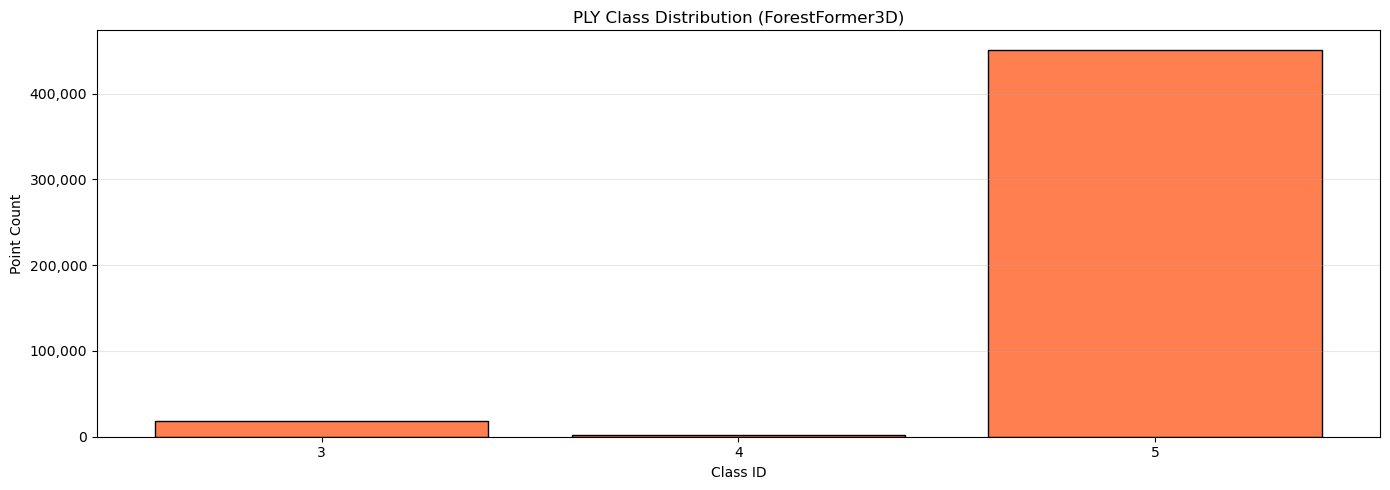


Class distribution (sample PLY):
    3:       17,875  ( 3.79%)
    4:        2,492  ( 0.53%)
    5:      451,310  (95.68%)

✅ Both formats should show identical class distributions
   (NPZ includes IGNORE_INDEX points, PLY excludes them)


In [10]:
# Title: Code: if all_ply:

if all_ply:
    from pathlib import Path
    import matplotlib.ticker as mticker

    # Ensure we have a dataframe to plot from (load first PLY if needed)
    if "df_ply" not in globals() or df_ply is None or len(df_ply) == 0:
        sample_ply = Path(all_ply[0])
        df_ply = PyntCloud.from_file(str(sample_ply)).points
        print(f"📂 Loaded sample for plotting: {sample_ply.name} ({len(df_ply):,} points)")

    # Class distribution from PLY (sample)
    class_counts = df_ply["semantic_seg"].value_counts().sort_index()

    fig, ax = plt.subplots(1, 1, figsize=(14, 5))
    ax.bar(class_counts.index.astype(int), class_counts.values, color="coral", edgecolor="black")
    ax.set_xlabel("Class ID")
    ax.set_ylabel("Point Count")
    ax.set_title("PLY Class Distribution (ForestFormer3D)")
    ax.grid(True, alpha=0.3, axis="y")

    # Make x-axis show integer class IDs cleanly
    ax.set_xticks(class_counts.index.astype(int))
    ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))

    # Make y-axis easier to read
    ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))

    plt.tight_layout()
    plt.show()

    # Print counts + percentages (sample)
    total = int(class_counts.sum())
    print("\nClass distribution (sample PLY):")
    for cls_id, cnt in class_counts.items():
        pct = 100.0 * float(cnt) / float(total) if total else 0.0
        print(f"  {int(cls_id):>3d}: {int(cnt):>12,}  ({pct:5.2f}%)")

    print("\n✅ Both formats should show identical class distributions")
    print("   (NPZ includes IGNORE_INDEX points, PLY excludes them)")
else:
    print("❌ No PLY files available. Run the batch processing cell first.")

In [11]:
# Title: Sanity checks — compare LAS vs PLY ranges

import numpy as np
import laspy
from pyntcloud import PyntCloud
from pathlib import Path

def resolve_las_path(path: Path) -> Path:
    candidates: list[Path] = [path]
    s = str(path)
    if "_m_" in s:
        candidates.append(Path(s.replace("_m_", "_")))
    else:
        if "znorm_3Dlabels_" in s:
            candidates.append(Path(s.replace("znorm_3Dlabels_", "znorm_3Dlabels_m_")))
        if "3Dlabels_" in s and "3Dlabels_m_" not in s:
            candidates.append(Path(s.replace("3Dlabels_", "3Dlabels_m_")))
    seen = set()
    uniq: list[Path] = []
    for c in candidates:
        cs = str(c)
        if cs in seen:
            continue
        seen.add(cs)
        uniq.append(c)
    for c in uniq:
        if c.exists():
            return c
    raise FileNotFoundError("Tried:\n  " + "\n  ".join(str(c) for c in uniq))

def check_las(las_path):
    las = laspy.read(str(las_path))
    xyz = np.c_[las.x, las.y, las.z]
    print("LAS:", las_path)
    print("  XYZ min:", xyz.min(axis=0))
    print("  XYZ max:", xyz.max(axis=0))
    print("  XYZ range:", xyz.max(axis=0) - xyz.min(axis=0))
    print("  Z std:", xyz[:, 2].std())

def check_ply(ply_path):
    df = PyntCloud.from_file(str(ply_path)).points
    xyz = df[["x", "y", "z"]].to_numpy(float)
    print("PLY:", ply_path)
    print("  XYZ min:", xyz.min(axis=0))
    print("  XYZ max:", xyz.max(axis=0))
    print("  XYZ range:", xyz.max(axis=0) - xyz.min(axis=0))
    print("  Z std:", xyz[:, 2].std())
    if "z_norm" in df.columns:
        zn = df["z_norm"].to_numpy(float)
        print("  z_norm range:", (zn.min(), zn.max()))

# --- set paths (use either convention) ---
las_orig = resolve_las_path(
    Path("/data/calperumResearch/site1_1_DD0001/lidar_l2/clipped/3d_structure_mask_malleid/znorm_3Dlabels_109.las")
)

las_from_ply = Path(
    "/data/calperumResearch/site1_1_DD0001/lidar_l2/clipped/preprocessed/reconstructed_las/znorm_3Dlabels_109_from_ply.las"
 )

ply_in = Path(
    "/data/calperumResearch/site1_1_DD0001/lidar_l2/clipped/preprocessed/forestformer3d_ply/znorm_3Dlabels_109.ply"
 )

# --- run checks ---
if las_orig.exists():
    check_las(las_orig)

if las_from_ply.exists():
    check_las(las_from_ply)

if ply_in.exists():
    check_ply(ply_in)

LAS: /data/calperumResearch/site1_1_DD0001/lidar_l2/clipped/3d_structure_mask_malleid/znorm_3Dlabels_109.las
  XYZ min: [4.61771530e+05 6.23750615e+06 5.95400000e+01]
  XYZ max: [4.61802230e+05 6.23753685e+06 6.52500000e+01]
  XYZ range: [30.7  30.7   5.71]
  Z std: 0.8973497216896325
PLY: /data/calperumResearch/site1_1_DD0001/lidar_l2/clipped/preprocessed/forestformer3d_ply/znorm_3Dlabels_109.ply
  XYZ min: [0. 0. 0.]
  XYZ max: [30.70000076 30.70000076  5.71000004]
  XYZ range: [30.70000076 30.70000076  5.71000004]
  Z std: 0.8973497218364282
  z_norm range: (0.0, 5.179999828338623)
